# A small cube from a huge scan, out of core

A 7 T MRI of a human hemisphere, and the same hemisphere scanned by synchrotron X-ray phase-contrast tomography
(HiP-CT): **976 GB at 20 µm**. We choose a small cube in the MRI and fill it with the synchrotron data at full
resolution, through an affine and a B-spline. ngff-zarr does it lazily, and reads only the part of the scan the cube
needs.

The data: subject Hb1 of the LINC project, [DANDI 001278](https://dandiarchive.org/dandiset/001278) (CC-BY 4.0), read
from DANDI's public S3 as OME-Zarr. Nothing is downloaded first.

## The principle

A resample fills each voxel *x* of the output grid with the moving image at *T(x)*. ngff-zarr cuts the output into
blocks, and before it reads a byte, works out where *T* sends each block:

- through an **affine**, the block's corners are enough;
- through a **B-spline**, a point moves by a weighted average of the control points around it, so those control
  points bound where the block can land;
- a margin covers what the interpolator reads around each point.

Each block then reads only the moving chunks inside its box, all in one Dask graph. The moving image is never loaded:
the cost follows the size of the cube, not the size of the scan.

## 1. Two images, read where they are

In [1]:
from hemisphere import MRI, XPCT, pyramid

for name, url in (("MRI", MRI), ("synchrotron", XPCT)):
    level0 = pyramid(url).images[0]
    voxel = level0.scale["x"] * (1000 if name == "MRI" else 1)
    print(f"{name}: {len(pyramid(url).images)} levels, level 0 {level0.data.shape} at {voxel:.2f} um, "
          f"{level0.data.nbytes / 1e9:,.1f} GB")

MRI: 6 levels, level 0 (1, 1280, 768, 1536) at 119.73 um, 6.0 GB


synchrotron: 8 levels, level 0 (7569, 7569, 8514) at 20.07 um, 975.5 GB


## 2. The transformation: an affine, then a B-spline

The MRI file carries a sform: an affine that places it in the synchrotron's frame, LINC's own alignment. On top of it,
a smooth cubic B-spline corrects what an affine cannot: 1,296 parameters, control points every 30 mm.
[make_bspline.py](make_bspline.py) shows where it comes from (a registration with IMPACT-Reg); here it only has to be
credible. Both are ITK transform files; composed, they are one ITK transform, which ngff-zarr takes as it is.

In [2]:
import itk

transform = itk.CompositeTransform[itk.D, 3].New()  # applies the transform added last first: the B-spline, then the sform
for path in ("sform.h5", "bspline.h5"):
    transform.AddTransform(itk.transformread(path)[0])

On the whole hemisphere, at a coarse level (a few seconds): the synchrotron in magenta over the MRI in green, without
a transform, through the affine, through both; then how far the B-spline moves each point. The two contrasts are
inverted (grey matter is bright in the MRI, white matter in the synchrotron), so agreement shows as interleaved
colours, not as white.

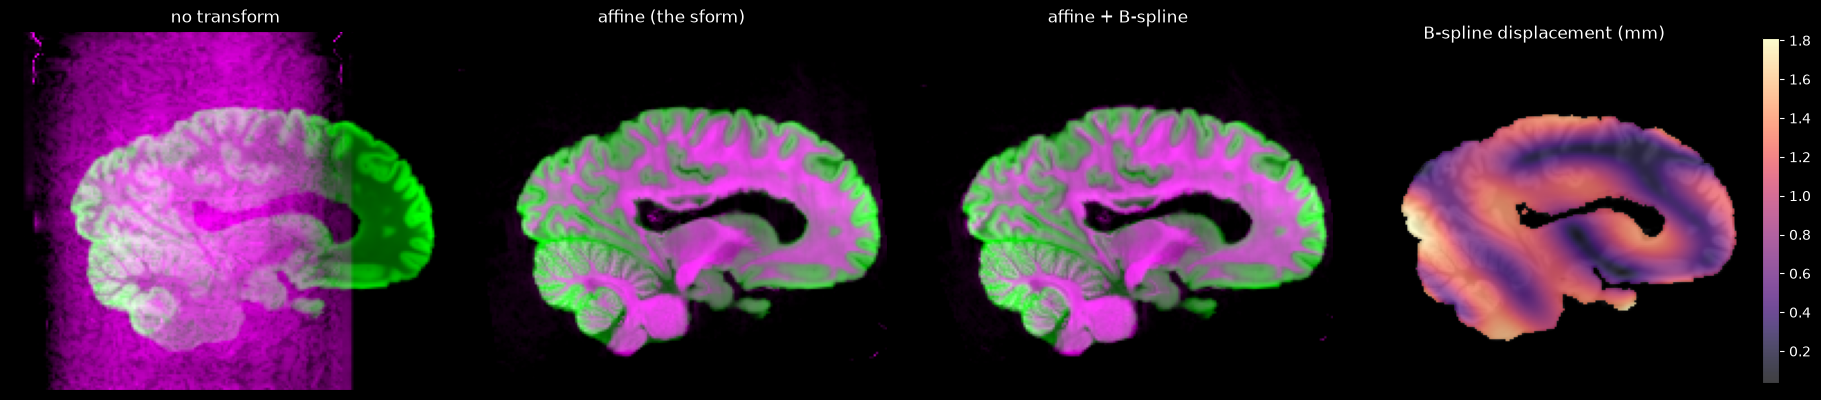

In [3]:
from hemisphere import show_alignment

show_alignment(transform);

## 3. A cube, chosen in the MRI

399^3 voxels at 20 um: only its geometry is used, its pixels are never read


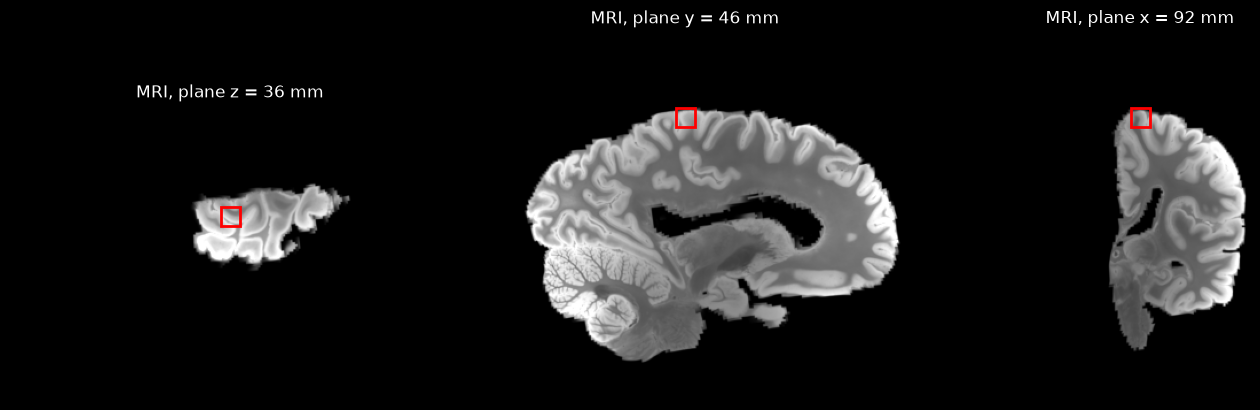

In [4]:
from hemisphere import grid, show_cube_in_mri

SIZE_MM = 8.0
cube = grid(centre_mm=(36.0, 46.4, 92.4), size_mm=SIZE_MM, spacing_mm=0.02007)  # (z, y, x), mm; the scan's voxel
print(f"{cube.data.shape[0]}^3 voxels at 20 um: only its geometry is used, its pixels are never read")
show_cube_in_mri(cube);

## 4. What the resample reads

466 chunks of 1,897,574 read: 0.24 GB of 976 GB (2.5e-04); voxel 20.07 um


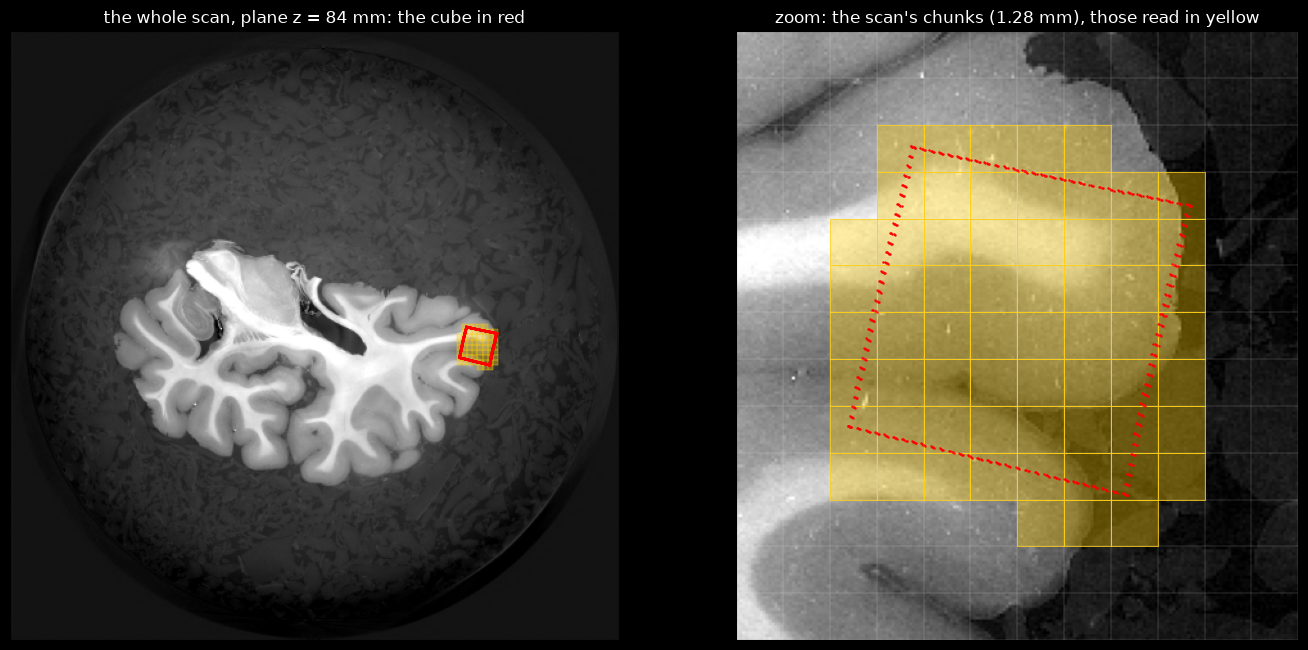

In [5]:
import ngff_zarr as nz
from hemisphere import show_reads, xpct

moving = xpct(0)  # the full-resolution scan, 976 GB: a lazy view
moved = nz.resample(transform, cube, moving)  # lazy: the blocks and their boxes are worked out, nothing is read
show_reads(transform, cube, moved, moving);

In the scan, the cube is a slightly turned and bent box (red). The resample reads the chunks around it (yellow) and
nothing else.

## 5. Compute it

(399, 399, 399), 127 MB, in 18 s


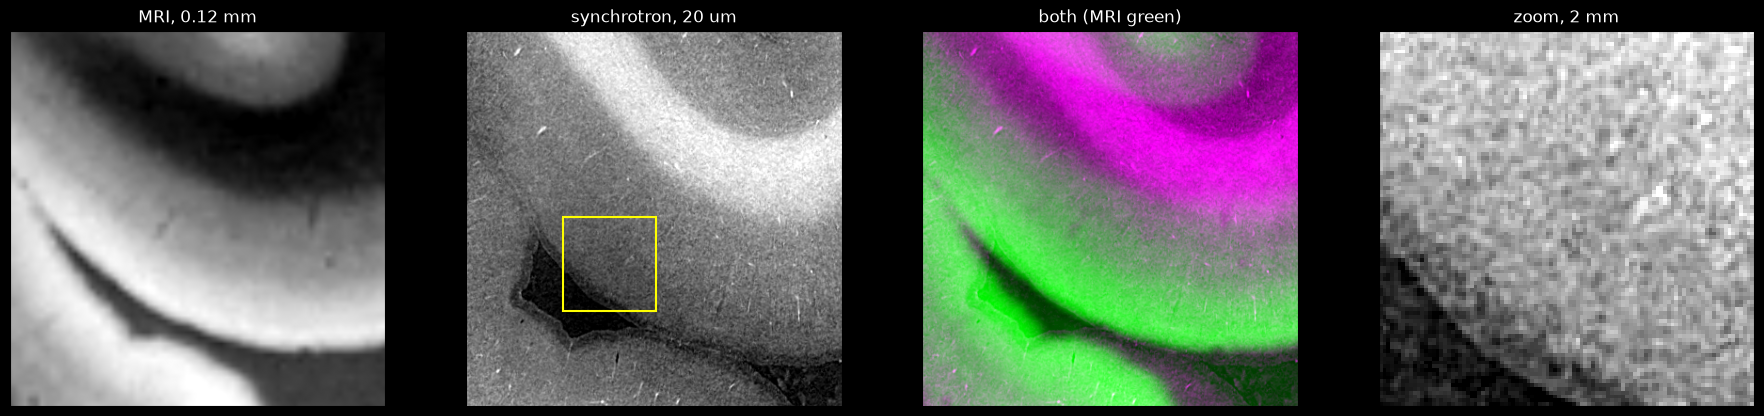

In [6]:
import time

import numpy as np
from hemisphere import mri, show_cube

start = time.time()
xpct_cube = np.asarray(moved.data)
print(f"{xpct_cube.shape}, {xpct_cube.nbytes / 1e6:.0f} MB, in {time.time() - start:.0f} s")
mri_cube = np.asarray(nz.resample(itk.IdentityTransform[itk.D, 3].New(), cube, mri(0)).data)  # the MRI, same grid
show_cube(mri_cube, xpct_cube, SIZE_MM);

The MRI and the synchrotron disagree on contrast and agree on anatomy: the gyrus, its white-matter core, the sulcus.
At 20 µm the synchrotron also shows the vessels.

`moved` is an ordinary lazy NgffImage: `nz.to_ngff_zarr` writes it block by block, and a larger cube costs a larger
read, never the whole scan.

## 6. In one command

[steps/resample.py](../../steps/resample.py) does all of this from the command line: two images and a sequence of
ITK transforms, applied in the order given, from the fixed image's points to the moving image's. Here the fixed image
is a cube cut out of the MRI, 0.12 mm, and `--spacing` fills it at the scan's 20 µm.

In [7]:
!python crop_mri.py 36.0 46.4 92.4 8 output/mri_cube.ome.zarr
!python ../../steps/resample.py output/mri_cube.ome.zarr {XPCT} bspline.h5 sform.h5 -o output/cube.ome.zarr \
    --spacing 0.02007 --storage-options '{{"skip_signature": true, "region": "us-east-2"}}'

output/mri_cube.ome.zarr: (67, 68, 68) voxels of 0.120 mm


(401, 406, 406) voxels at 20.07 um, read from moving level 0 (20.07 um), through 2 transform(s)


output/cube.ome.zarr, written in 19 s
